# RAG Uncertainty Eval: Multilingual Dataset Construction

**This notebook:**
1. Audits all 15 MIRACL languages; keeps those with ≥ `MIN_QUERIES` queries that have ≥1 positive passage
2. For each qualifying language: loads corpus, queries, qrels and builds a flat `(query, distractor)` table; passages outside the p2–p98 text-length band per language are dropped
3. Constructs **two gold references** per query:
   - `gold_judge_text` — all annotated positive passages concatenated (seen only by the LLM judge, never by the generator)
   - `gold_generation_text` — one randomly sampled positive (used as the correct context in the *distractor+gold* generation condition)
4. Scores each (distractor, gold) pair with **two difficulty metrics**:
   - `tfidf_sim` — lexical: TF-IDF cosine similarity, fitted independently per language
   - `semantic_sim` — semantic: cosine similarity of `google/gemma-embedding-300m` embeddings
5. Removes **near-duplicate distractors** (semantic_sim ≥ p95 per language) that are so similar to the gold they likely contain the answer, contaminating the distractor-only condition
6. Assigns **per-language** difficulty tiers (Easy / Medium / Hard) using within-language tertiles of the compound score `tfidf_sim + (semantic_sim+1)/2`; both raw scores are retained for regression analysis
7. Derives **one evaluation set** stratified by compound difficulty: three distractors per query (one per tier), enabling within-query comparison while controlling for query-level confounders
8. Saves per-language CSVs, a combined multilingual full CSV, the evaluation set CSV, and difficulty thresholds
9. EDA: language coverage, score distributions, TF-IDF vs semantic correlation, per-language tier balance, qualitative examples

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer

import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel

sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_colwidth', 120)

In [44]:
# ── Experiment constants ──────────────────────────────────────────────────────
DATASET               = 'datalama/miracl-hard-negatives'
EMBED_MODEL           = 'google/embeddinggemma-300m'
SEED                  = 42
MIN_QUERIES           = 100         # drop languages with fewer qualifying queries
DISTRACTOR_LEN_PCTILE = (2, 98)    # keep passages within this text-length percentile band
NEAR_DUP_SIM_PCTILE   = 95         # drop distractors above this semantic_sim percentile per language
EMBED_BATCH           = 64          # passages per GPU batch
PASSAGE_SEP           = '\n\n'      # separator used when concatenating positive passages

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device: {DEVICE}')

DATA_DIR = Path('../data')
LANG_DIR = DATA_DIR / 'by_language'
DATA_DIR.mkdir(exist_ok=True)
LANG_DIR.mkdir(exist_ok=True)

ALL_MIRACL_LANGS = [
    'ar', 'de', 'en', 'es', 'fa',
    'fi', 'fr', 'hi', 'id', 'ja', 'ko',
    'ru', 'te', 'th', 'zh',
]

Device: cuda


## 1  Language Audit

Load qrels for every MIRACL language, count queries that have at least one annotated positive passage,
and drop languages below `MIN_QUERIES`.

In [4]:
def count_qualified_queries(lang):
    try:
        qrels = load_dataset(DATASET, lang, split='dev').to_pandas()
        qrels = qrels.rename(columns={'query-id': 'query_id', 'corpus-id': 'corpus_id'})
        return int(qrels[qrels['score'] == 1]['query_id'].nunique())
    except Exception:
        return 0


print('Auditing MIRACL languages ...')
audit_rows = []
for lang in ALL_MIRACL_LANGS:
    n = count_qualified_queries(lang)
    included = n >= MIN_QUERIES
    audit_rows.append({'language': lang, 'n_queries': n, 'included': included})
    tag = 'OK  ' if included else 'SKIP'
    print(f'  [{tag}] {lang:3s}: {n:4d} queries with positives')

audit_df = pd.DataFrame(audit_rows)
QUALIFYING_LANGS = audit_df.loc[audit_df['included'], 'language'].tolist()
print(f'\nQualifying languages ({len(QUALIFYING_LANGS)}): {QUALIFYING_LANGS}')

Auditing MIRACL languages ...
  [OK  ] ar : 1000 queries with positives
  [OK  ] de :  305 queries with positives
  [OK  ] en :  799 queries with positives
  [OK  ] es :  648 queries with positives
  [OK  ] fa :  632 queries with positives
  [OK  ] fi : 1000 queries with positives
  [OK  ] fr :  343 queries with positives
  [OK  ] hi :  350 queries with positives
  [OK  ] id :  960 queries with positives
  [OK  ] ja :  860 queries with positives
  [OK  ] ko :  213 queries with positives
  [OK  ] ru : 1000 queries with positives
  [OK  ] te :  828 queries with positives
  [OK  ] th :  733 queries with positives
  [OK  ] zh :  393 queries with positives

Qualifying languages (15): ['ar', 'de', 'en', 'es', 'fa', 'fi', 'fr', 'hi', 'id', 'ja', 'ko', 'ru', 'te', 'th', 'zh']


## 2  Per-Language Data Loading & Gold Construction

For each qualifying language:
- Join qrels ← corpus (passage text, title) ← queries (query text)
- **`gold_judge_text`**: concatenate all positive passages sorted deterministically by corpus_id.
  Gives the judge complete evidence, reducing false HALLUCINATE labels when the answer appears
  in any of the multiple annotated positives.
- **`gold_generation_text`**: randomly sample one positive passage (reproducible, `SEED`).
  Used as the retrieved correct context in the *distractor+gold* generation condition;
  simulates realistic single-passage RAG retrieval.
- No difficulty-based sampling here — all `(query, distractor)` pairs are retained.

In [6]:
def load_language(lang):
    """Return a flat (query, distractor) DataFrame for one MIRACL language."""
    corpus  = load_dataset(DATASET, f'corpus-{lang}',  split='corpus').to_pandas()
    queries = load_dataset(DATASET, f'queries-{lang}', split='queries').to_pandas()
    qrels   = load_dataset(DATASET,  lang,             split='dev').to_pandas()

    corpus  = corpus.rename(columns={'_id': 'corpus_id'})
    if 'title' not in corpus.columns:
        corpus['title'] = ''
    queries = queries.rename(columns={'_id': 'query_id', 'text': 'query'})
    qrels   = qrels.rename(columns={'query-id': 'query_id', 'corpus-id': 'corpus_id'})

    joined    = qrels.merge(corpus, on='corpus_id', how='left')
    joined    = joined.merge(queries[['query_id', 'query']], on='query_id', how='left')

    positives = joined[joined['score'] == 1].copy().sort_values(['query_id', 'corpus_id'])
    negatives = joined[joined['score'] == 0].copy()

    # ── Filter positives by per-language length band ──────────────────────────
    lo, hi     = DISTRACTOR_LEN_PCTILE
    pos_lens   = positives['text'].str.strip().str.len().fillna(0)
    valid_pos  = pos_lens[pos_lens > 0]
    pos_min    = int(np.percentile(valid_pos, lo))
    pos_max    = int(np.percentile(valid_pos, hi))
    positives  = positives[(pos_lens >= pos_min) & (pos_lens <= pos_max)].copy()

    # ── gold_judge_text: all positives concatenated ───────────────────────────
    gold_judge = (
        positives
        .groupby('query_id', as_index=False)
        .agg(
            gold_judge_text=('text', lambda x: PASSAGE_SEP.join(x.fillna('').astype(str))),
            n_positives=('corpus_id', 'count'),
        )
    )

    # ── gold_generation_text: one randomly sampled positive ───────────────────
    rng     = np.random.default_rng(SEED)
    pos_tmp = positives.copy()
    pos_tmp['_rand'] = rng.random(len(pos_tmp))
    gold_gen = (
        pos_tmp
        .sort_values('_rand')
        .drop_duplicates(subset='query_id', keep='first')
        [['query_id', 'corpus_id', 'text']]
        .rename(columns={'corpus_id': 'gold_generation_id', 'text': 'gold_generation_text'})
    )

    # ── Keep only queries that have at least one positive ─────────────────────
    valid_qids = set(gold_judge['query_id'])
    negatives  = negatives[negatives['query_id'].isin(valid_qids)].copy()

    # ── Keep distractors within the per-language length percentile band ───────
    n_before   = len(negatives)
    text_lens  = negatives['text'].str.strip().str.len().fillna(0)
    valid_lens = text_lens[text_lens > 0]
    neg_min    = int(np.percentile(valid_lens, lo))
    neg_max    = int(np.percentile(valid_lens, hi))
    negatives  = negatives[(text_lens >= neg_min) & (text_lens <= neg_max)].copy()
    n_dropped  = n_before - len(negatives)
    print(f'    [{lang}] positives p{lo}–p{hi} = [{pos_min}, {pos_max}] chars'
          f' | distractors p{lo}–p{hi} = [{neg_min}, {neg_max}] chars'
          f' → dropped {n_dropped} distractors')

    n_neg = negatives.groupby('query_id').size().rename('n_negatives').reset_index()

    gold = (
        gold_judge
        .merge(gold_gen, on='query_id', how='left')
        .merge(n_neg,    on='query_id', how='left')
    )

    # ── Build flat (query, distractor) table ──────────────────────────────────
    df = (
        negatives
        .rename(columns={
            'corpus_id': 'distractor_id',
            'text':      'distractor_text',
            'title':     'distractor_title',
        })
        .merge(gold, on='query_id', how='left')
    )

    df['language']             = lang
    df['distractor_title']     = df['distractor_title'].fillna('')
    df['gold_judge_text']      = df['gold_judge_text'].fillna('')
    df['gold_generation_text'] = df['gold_generation_text'].fillna('')

    out_cols = [
        'language', 'query_id', 'query',
        'distractor_id', 'distractor_text', 'distractor_title',
        'gold_judge_text', 'gold_generation_text', 'gold_generation_id',
        'n_positives', 'n_negatives',
    ]
    return df[out_cols].reset_index(drop=True)

In [7]:
print('Loading qualifying languages ...')
lang_dfs = {}
for lang in QUALIFYING_LANGS:
    print(f'  {lang} ...', end=' ', flush=True)
    lang_dfs[lang] = load_language(lang)
    n_q = lang_dfs[lang]['query_id'].nunique()
    n_d = len(lang_dfs[lang])
    print(f'{n_q} queries  {n_d:,} distractors')

df_full = pd.concat(lang_dfs.values(), ignore_index=True)

n_langs   = df_full['language'].nunique()
n_queries = df_full['query_id'].nunique()
print(f'\nTotal: {len(df_full):,} rows | {n_langs} languages | {n_queries:,} unique queries')

Loading qualifying languages ...
  ar ...     [ar] positives p2–p98 = [104, 1714] chars | distractors p2–p98 = [136, 1969] chars → dropped 1407 distractors
974 queries  6,477 distractors
  de ...     [de] positives p2–p98 = [107, 1629] chars | distractors p2–p98 = [85, 1647] chars → dropped 652 distractors
299 queries  1,663 distractors
  en ...     [en] positives p2–p98 = [152, 1839] chars | distractors p2–p98 = [146, 1819] chars → dropped 1015 distractors
766 queries  4,876 distractors
  es ...     [es] positives p2–p98 = [143, 1662] chars | distractors p2–p98 = [99, 1485] chars → dropped 855 distractors
588 queries  2,547 distractors
  fa ...     [fa] positives p2–p98 = [70, 1463] chars | distractors p2–p98 = [75, 1494] chars → dropped 1381 distractors
611 queries  3,715 distractors
  fi ...     [fi] positives p2–p98 = [127, 1267] chars | distractors p2–p98 = [188, 1513] chars → dropped 1482 distractors
916 queries  5,941 distractors
  fr ...     [fr] positives p2–p98 = [117, 1618] 

## 3  TF-IDF Similarity (per language)

Lexical difficulty baseline — mirrors the original English pipeline.
A separate TF-IDF vectoriser is fitted per language to avoid cross-language vocabulary pollution.
Similarity is computed between `distractor_text` and `gold_judge_text`.

**Tokenization strategy:**
- Latin/Cyrillic/Arabic scripts (`ar`, `de`, `en`, `es`, `fa`, `fi`, `fr`, `hi`, `id`, `ru`, `te`): word unigrams + bigrams (`analyzer='word'`, `ngram_range=(1,2)`) — standard whitespace tokenisation.
- Scripts without whitespace word boundaries (`ja`, `zh`, `th`, `ko`): character bigrams + trigrams (`analyzer='char_wb'`, `ngram_range=(2,3)`) — treats each character sequence as a lexical unit, recovering meaningful overlap that whitespace tokenisation misses entirely.

In [8]:
# Languages without whitespace word boundaries — use character n-grams instead
CHAR_NGRAM_LANGS = {'ja', 'zh', 'th', 'ko'}

df_full['tfidf_sim'] = 0.0

for lang in tqdm(QUALIFYING_LANGS, desc='TF-IDF'):
    idx     = df_full.index[df_full['language'] == lang]
    lang_df = df_full.loc[idx]

    all_texts = list({
        *lang_df['distractor_text'].tolist(),
        *lang_df['gold_judge_text'].tolist(),
    })
    all_texts = [t for t in all_texts if t]

    if lang in CHAR_NGRAM_LANGS:
        vec = TfidfVectorizer(
            max_features=30_000, sublinear_tf=True,
            analyzer='char_wb', ngram_range=(2, 3),
        )
    else:
        vec = TfidfVectorizer(
            max_features=30_000, sublinear_tf=True,
            ngram_range=(1, 2),
        )
    vec.fit(all_texts)

    d_vecs = vec.transform(lang_df['distractor_text'])
    g_vecs = vec.transform(lang_df['gold_judge_text'])

    dots    = np.array(d_vecs.multiply(g_vecs).sum(axis=1)).flatten()
    norms_d = np.sqrt(np.array(d_vecs.power(2).sum(axis=1)).flatten())
    norms_g = np.sqrt(np.array(g_vecs.power(2).sum(axis=1)).flatten())
    denom   = norms_d * norms_g
    sims    = np.where(denom > 0, dots / denom, 0.0).round(6)

    df_full.loc[idx, 'tfidf_sim'] = sims

tfidf_mean   = df_full['tfidf_sim'].mean()
tfidf_median = df_full['tfidf_sim'].median()
tfidf_max    = df_full['tfidf_sim'].max()
print(f'TF-IDF sim — mean: {tfidf_mean:.4f}  median: {tfidf_median:.4f}  max: {tfidf_max:.4f}')
print(f'\nAnalyzer used per language:')
for lang in QUALIFYING_LANGS:
    mode = 'char_wb (2,3)' if lang in CHAR_NGRAM_LANGS else 'word   (1,2)'
    print(f'  {lang:3s}: {mode}')

TF-IDF:   0%|          | 0/15 [00:00<?, ?it/s]

TF-IDF sim — mean: 0.1625  median: 0.1458  max: 1.0000

Analyzer used per language:
  ar : word   (1,2)
  de : word   (1,2)
  en : word   (1,2)
  es : word   (1,2)
  fa : word   (1,2)
  fi : word   (1,2)
  fr : word   (1,2)
  hi : word   (1,2)
  id : word   (1,2)
  ja : char_wb (2,3)
  ko : char_wb (2,3)
  ru : word   (1,2)
  te : word   (1,2)
  th : char_wb (2,3)
  zh : char_wb (2,3)


## 4  Semantic Similarity — Gemma Embeddings

Dense difficulty signal using `google/gemma-embedding-300m`.
All unique passage texts are embedded in a single pass (no re-encoding of repeated passages).
Mean pooling over the last hidden state, followed by L2 normalisation; cosine similarity
then equals the dot product of the normalised vectors.

In [9]:
from sentence_transformers import SentenceTransformer

print(f'Loading {EMBED_MODEL} ...')
embed_model = SentenceTransformer(EMBED_MODEL, device=DEVICE)
print('Model loaded.')


def encode(texts: list, batch_size: int = EMBED_BATCH) -> np.ndarray:
    return embed_model.encode_document(
        texts,
        batch_size=batch_size,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

Skipping import of cpp extensions due to incompatible torch version 2.12.0.dev20260325+cu130 for torchao version 0.16.0             Please see https://github.com/pytorch/ao/issues/2919 for more info


Loading google/embeddinggemma-300m ...


Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Model loaded.


In [18]:
# Collect all unique passage texts across all languages to embed in one pass
all_texts_combined = pd.concat([
    df_full['distractor_text'],
    df_full['gold_judge_text'],
])
unique_texts = all_texts_combined.unique().tolist()
print(f'Unique passages to embed: {len(unique_texts):,}')

print('Encoding all unique passages ...')
embeddings = encode(unique_texts)

text2idx = {t: i for i, t in enumerate(unique_texts)}

d_idx = [text2idx[t] for t in df_full['distractor_text']]
g_idx = [text2idx[t] for t in df_full['gold_judge_text']]

d_embs = embeddings[d_idx]   # (N, dim)
g_embs = embeddings[g_idx]   # (N, dim)

# Cosine similarity = dot product of L2-normalised vectors
df_full['semantic_sim'] = (d_embs * g_embs).sum(axis=1).round(6)

sem_mean   = df_full['semantic_sim'].mean()
sem_median = df_full['semantic_sim'].median()
sem_max    = df_full['semantic_sim'].max()
print(f'Semantic sim — mean: {sem_mean:.4f}  median: {sem_median:.4f}  max: {sem_max:.4f}')

Unique passages to embed: 62,450
Encoding all unique passages ...


Batches:   0%|          | 0/976 [00:00<?, ?it/s]

Semantic sim — mean: 0.5185  median: 0.5256  max: 1.0000


## 4.1  Near-Duplicate Distractor Removal

Distractors with very high semantic similarity to the gold passage are likely annotation near-duplicates: passages from the same Wikipedia section that contain the answer but were not annotated as relevant, or corpus entries that are textually near-identical to a positive. Including them would contaminate the distractor-only experimental condition — the model could answer correctly not by reasoning from context but because the distractor itself contains the answer.

**Removal criterion**: distractors above the **per-language p95 of `semantic_sim`** are dropped. This conservative threshold targets only the top 5% by semantic overlap with gold, removing the most egregious near-duplicates while preserving the legitimately hard distractors that make up the upper difficulty tier.

In [45]:
rows_before = len(df_full)
drop_stats  = []

for lang in QUALIFYING_LANGS:
    mask      = df_full['language'] == lang
    threshold = df_full.loc[mask, 'semantic_sim'].quantile(NEAR_DUP_SIM_PCTILE / 100)
    near_dups = mask & (df_full['semantic_sim'] >= threshold)
    n_drop    = near_dups.sum()
    drop_stats.append({'language': lang, 'sem_sim_p95': round(threshold, 4), 'dropped': n_drop})
    df_full   = df_full[~near_dups].reset_index(drop=True)

print(f'Removed {rows_before - len(df_full):,} near-duplicate distractors '
      f'(semantic_sim ≥ p{NEAR_DUP_SIM_PCTILE} per language)\n')
print(pd.DataFrame(drop_stats).to_string(index=False))

Removed 2,814 near-duplicate distractors (semantic_sim ≥ p95 per language)

language  sem_sim_p95  dropped
      ar       0.7582      324
      de       0.7328       84
      en       0.7367      244
      es       0.7288      128
      fa       0.7625      186
      fi       0.7537      298
      fr       0.7499      106
      hi       0.7225      113
      id       0.7283      273
      ja       0.7290      273
      ko       0.7658       98
      ru       0.7526      274
      te       0.7911       27
      th       0.7460      266
      zh       0.7746      120


## 5  Compound Difficulty Score & Per-Language Tiers

**Compound score**: `compound_sim = tfidf_sim + (semantic_sim + 1) / 2`

`tfidf_sim` is bounded [0, 1] while `semantic_sim` spans [-1, 1]. To give both metrics equal weight, `semantic_sim` is rescaled to [0, 1] before summing, making `compound_sim` ∈ [0, 2]. Both raw scores are retained as-is for regression analysis; the rescaling applies only when computing `compound_sim`.

**Per-language tiers**: Easy / Medium / Hard tertile thresholds are computed **independently within each language**. This ensures the tier distribution is balanced ~1:1:1 regardless of absolute score differences across languages or scripts.

In [47]:
# ── Compound score ────────────────────────────────────────────────────────────
# tfidf_sim ∈ [0, 1]; semantic_sim ∈ [-1, 1] — rescale semantic to [0, 1] first
# so both metrics contribute equally (same range) to the compound score
df_full['compound_sim'] = (df_full['tfidf_sim'] + (df_full['semantic_sim'] + 1) / 2).round(6)

# ── Per-language tertile tiers ────────────────────────────────────────────────
lang_thresh = {}
df_full['difficulty'] = ''

for lang in QUALIFYING_LANGS:
    mask   = df_full['language'] == lang
    scores = df_full.loc[mask, 'compound_sim']
    q33, q67 = scores.quantile([1/3, 2/3])
    lang_thresh[lang] = {'q33': round(q33, 6), 'q67': round(q67, 6)}
    tiers = pd.cut(
        scores,
        bins=[-np.inf, q33, q67, np.inf],
        labels=['easy', 'medium', 'hard'],
    ).astype(str)
    df_full.loc[mask, 'difficulty'] = tiers.values

# ── Save per-language thresholds ──────────────────────────────────────────────
thresh_df = pd.DataFrame([
    {'language': lang, 'compound_q33': v['q33'], 'compound_q67': v['q67']}
    for lang, v in lang_thresh.items()
])
thresh_df.to_csv(DATA_DIR / 'difficulty_thresholds.csv', index=False)
print('Per-language compound_sim thresholds:')
print(thresh_df.to_string(index=False))

print('\nDifficulty distribution (all languages combined):')
print(df_full['difficulty'].value_counts().sort_index().to_string())
print('\nCompound sim stats (range is [0, 2] after rescaling):')
cs = df_full['compound_sim']
print(f'  mean={cs.mean():.4f}  median={cs.median():.4f}  min={cs.min():.4f}  max={cs.max():.4f}')

Per-language compound_sim thresholds:
language  compound_q33  compound_q67
      ar      0.815570      0.941185
      de      0.825659      0.918605
      en      0.875751      0.998216
      es      0.846016      0.950316
      fa      0.850490      0.966512
      fi      0.818646      0.932384
      fr      0.848012      0.952639
      hi      0.741493      0.851445
      id      0.828573      0.948793
      ja      0.868444      0.992903
      ko      0.887133      1.008309
      ru      0.825326      0.934593
      te      0.695472      0.791934
      th      0.925063      1.055725
      zh      0.855910      0.984887

Difficulty distribution (all languages combined):
difficulty
easy      17777
hard      17775
medium    17766

Compound sim stats (range is [0, 2] after rescaling):
  mean=0.9061  median=0.9013  min=0.4918  max=1.6513


## 6  Evaluation Set Construction

For each query we select **three distractors — one per difficulty tier** — enabling a within-query
comparison: the same factual question is presented to the model with an Easy, Medium, and Hard
distractor in separate runs. This controls for query-level confounders (topic familiarity, answer
frequency in pre-training) and lets us attribute differences in hallucination rate directly to
distractor difficulty rather than to variation across questions.

**Pipeline:**
1. **Filter** to queries that have at least one distractor in *each* of the three tiers — incomplete triples are excluded.
2. **Select** one distractor per tier per query **at random** (reproducible via `SEED`). Random selection gives each tier's central tendency rather than always picking boundary cases, producing cleaner average separation between tiers and unbiased difficulty estimates for regression analysis.
3. **Subsample** `K` queries per language to control inference cost, sampling at the *query* level so all three tiers of a selected query are always included together.

In [ ]:
K = 100   # queries per language

# 1. Keep only (language, query_id) pairs with a distractor in every tier
tier_coverage = (
    df_full
    .groupby(['language', 'query_id', 'difficulty'])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=['easy', 'medium', 'hard'], fill_value=0)
    .reset_index()
)
complete_pairs = tier_coverage[
    (tier_coverage['easy']   > 0) &
    (tier_coverage['medium'] > 0) &
    (tier_coverage['hard']   > 0)
][['language', 'query_id']]

df_complete = df_full.merge(complete_pairs, on=['language', 'query_id'], how='inner')

# 2. Random distractor per (language, query, tier)
triples = (
    df_complete
    .groupby(['language', 'query_id', 'difficulty'], observed=True)
    .sample(n=1, random_state=SEED)
    .reset_index(drop=True)
)

# 3. Sample K queries per language — preserves the within-query triple
sampled_keys = (
    triples[triples['difficulty'] == 'easy']
    .groupby('language', group_keys=False)
    .apply(lambda g: g.sample(min(K, len(g)), random_state=SEED))
    [['language', 'query_id']]
    .reset_index(drop=True)
)

eval_df = (
    triples
    .merge(sampled_keys, on=['language', 'query_id'], how='inner')
    .reset_index(drop=True)
)

# 4. Drop languages that could not reach K complete triples
lang_query_counts = eval_df.groupby('language')['query_id'].nunique()
excluded_langs    = lang_query_counts[lang_query_counts < K].index.tolist()
if excluded_langs:
    print(f'Excluding languages with <{K} eval queries: {excluded_langs}')
    eval_df = eval_df[~eval_df['language'].isin(excluded_langs)].reset_index(drop=True)

n_rows = len(eval_df)
n_q    = eval_df.groupby(['language', 'query_id']).ngroups
print(f'Eval set: {n_rows:,} rows | {n_q:,} unique (language, query) pairs')
print('\nBy difficulty tier:')
print(eval_df['difficulty'].value_counts().sort_index().to_string())
print('\nBy language (rows):')
print(eval_df['language'].value_counts().sort_index().to_string())
print('\nBy language (unique queries):')
print(eval_df.groupby('language')['query_id'].nunique().sort_index().to_string())

## 7  Save Outputs

In [49]:
# Full multilingual dataset
full_path = DATA_DIR / 'rag_eval_multilingual_full.csv'
df_full.to_csv(full_path, index=False)
print(f'Saved full dataset  ({len(df_full):,} rows)  -> {full_path}')

# Evaluation set
eval_path = DATA_DIR / 'rag_eval_multilingual_eval.csv'
eval_df.to_csv(eval_path, index=False)
print(f'Saved eval set      ({len(eval_df):,} rows)  -> {eval_path}')

# Difficulty thresholds (already saved in Section 5)
print(f'Thresholds saved    -> {DATA_DIR}/difficulty_thresholds.csv')

# Per-language full files
for lang in QUALIFYING_LANGS:
    lang_df   = df_full[df_full['language'] == lang]
    lang_path = LANG_DIR / f'rag_eval_{lang}_full.csv'
    lang_df.to_csv(lang_path, index=False)
print(f'Per-language files  -> {LANG_DIR}/')

print('\nOutput columns (eval set):')
for col in eval_df.columns:
    print(f'  {col}')

Saved full dataset  (53,318 rows)  -> ../data/rag_eval_multilingual_full.csv
Saved eval set      (4,296 rows)  -> ../data/rag_eval_multilingual_eval.csv
Thresholds saved    -> ../data/difficulty_thresholds.csv
Per-language files  -> ../data/by_language/

Output columns (eval set):
  language
  query_id
  query
  distractor_id
  distractor_text
  distractor_title
  gold_judge_text
  gold_generation_text
  gold_generation_id
  n_positives
  n_negatives
  tfidf_sim
  semantic_sim
  compound_sim
  difficulty


## 8  EDA

### 8.1  Language Coverage

In [50]:
coverage = (
    df_full
    .groupby('language', as_index=False)
    .agg(
        n_queries=('query_id',       'nunique'),
        n_pairs=('distractor_id',    'count'),
        avg_tfidf_sim=('tfidf_sim',    'mean'),
        avg_semantic_sim=('semantic_sim', 'mean'),
        avg_compound_sim=('compound_sim', 'mean'),
    )
    .sort_values('n_queries', ascending=False)
    .reset_index(drop=True)
)
coverage['avg_tfidf_sim']    = coverage['avg_tfidf_sim'].round(4)
coverage['avg_semantic_sim'] = coverage['avg_semantic_sim'].round(4)
coverage['avg_compound_sim'] = coverage['avg_compound_sim'].round(4)

# Per-tier distractor counts (compound-based difficulty)
for tier in ['easy', 'medium', 'hard']:
    counts = (
        df_full[df_full['difficulty'] == tier]
        .groupby('language')['distractor_id']
        .count()
        .rename(f'{tier}_pairs')
    )
    coverage = coverage.merge(counts, on='language', how='left')

# Eval set query counts per language
eval_q_counts = (
    eval_df.groupby('language')['query_id']
    .nunique()
    .rename('eval_queries')
    .reset_index()
)
coverage = coverage.merge(eval_q_counts, on='language', how='left')
coverage['eval_queries'] = coverage['eval_queries'].fillna(0).astype(int)

display(coverage)

,language,n_queries,n_pairs,avg_tfidf_sim,avg_semantic_sim,avg_compound_sim,easy_pairs,medium_pairs,hard_pairs,eval_queries
0,ar,972,6153,0.1332,0.4955,0.8810,2051,2051,2051,100
1,ru,969,5204,0.1204,0.5265,0.8837,1735,1734,1735,100
2,fi,916,5643,0.1254,0.5108,0.8808,1881,1881,1881,100
3,id,912,5179,0.1504,0.4747,0.8877,1727,1726,1726,100
4,ja,782,5175,0.1793,0.5050,0.9318,1725,1725,1725,100
5,en,764,4632,0.1865,0.5075,0.9403,1544,1544,1544,100
6,th,714,5038,0.2390,0.5019,0.9900,1679,1680,1679,100
7,fa,610,3529,0.1527,0.5213,0.9133,1177,1176,1176,100
8,es,580,2419,0.1510,0.5002,0.9011,807,805,807,100
9,zh,385,2267,0.1523,0.5526,0.9286,757,754,756,100


### 8.2  Score Distributions

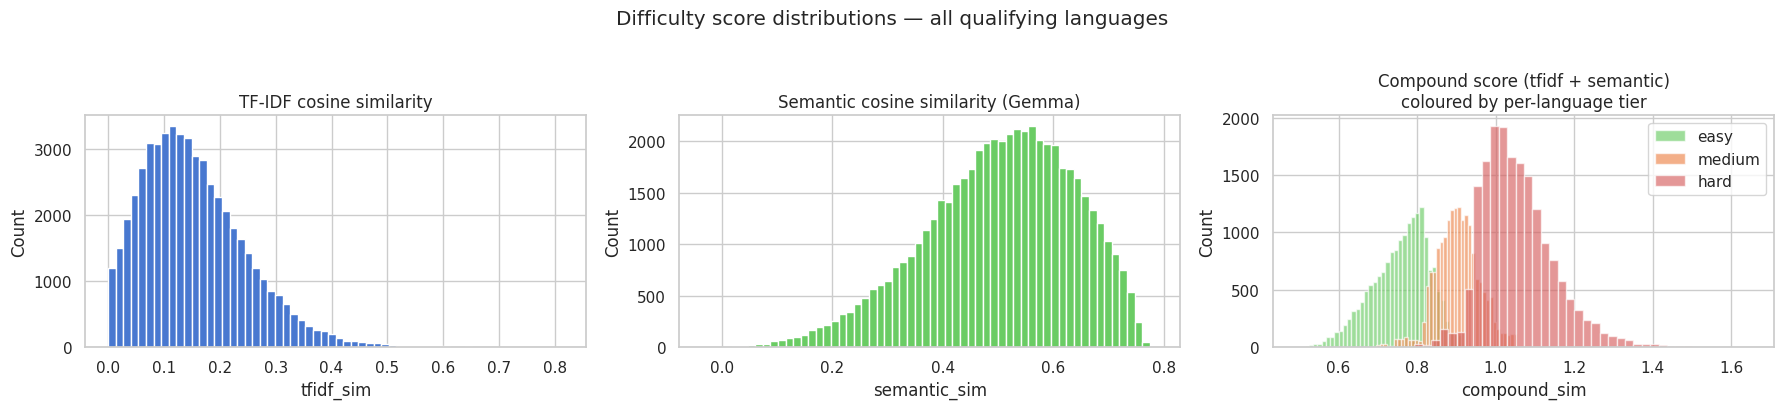

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
palette = sns.color_palette('muted')

# TF-IDF similarity
axes[0].hist(df_full['tfidf_sim'], bins=60, color=palette[0], edgecolor='white')
axes[0].set_title('TF-IDF cosine similarity')
axes[0].set_xlabel('tfidf_sim')
axes[0].set_ylabel('Count')

# Semantic similarity
axes[1].hist(df_full['semantic_sim'], bins=60, color=palette[2], edgecolor='white')
axes[1].set_title('Semantic cosine similarity (Gemma)')
axes[1].set_xlabel('semantic_sim')
axes[1].set_ylabel('Count')

# Compound score — coloured by difficulty tier
tier_colours = {'easy': palette[2], 'medium': palette[1], 'hard': palette[3]}
for tier, colour in tier_colours.items():
    subset = df_full[df_full['difficulty'] == tier]['compound_sim']
    axes[2].hist(subset, bins=40, alpha=0.65, color=colour,
                 edgecolor='white', label=tier)
axes[2].set_title('Compound score (tfidf + semantic)\ncoloured by per-language tier')
axes[2].set_xlabel('compound_sim')
axes[2].set_ylabel('Count')
axes[2].legend()

plt.suptitle('Difficulty score distributions — all qualifying languages', y=1.02)
plt.tight_layout()
plt.savefig(DATA_DIR / 'fig_score_distributions.png', dpi=120, bbox_inches='tight')
plt.show()

### 8.3  Per-Language Score Distributions

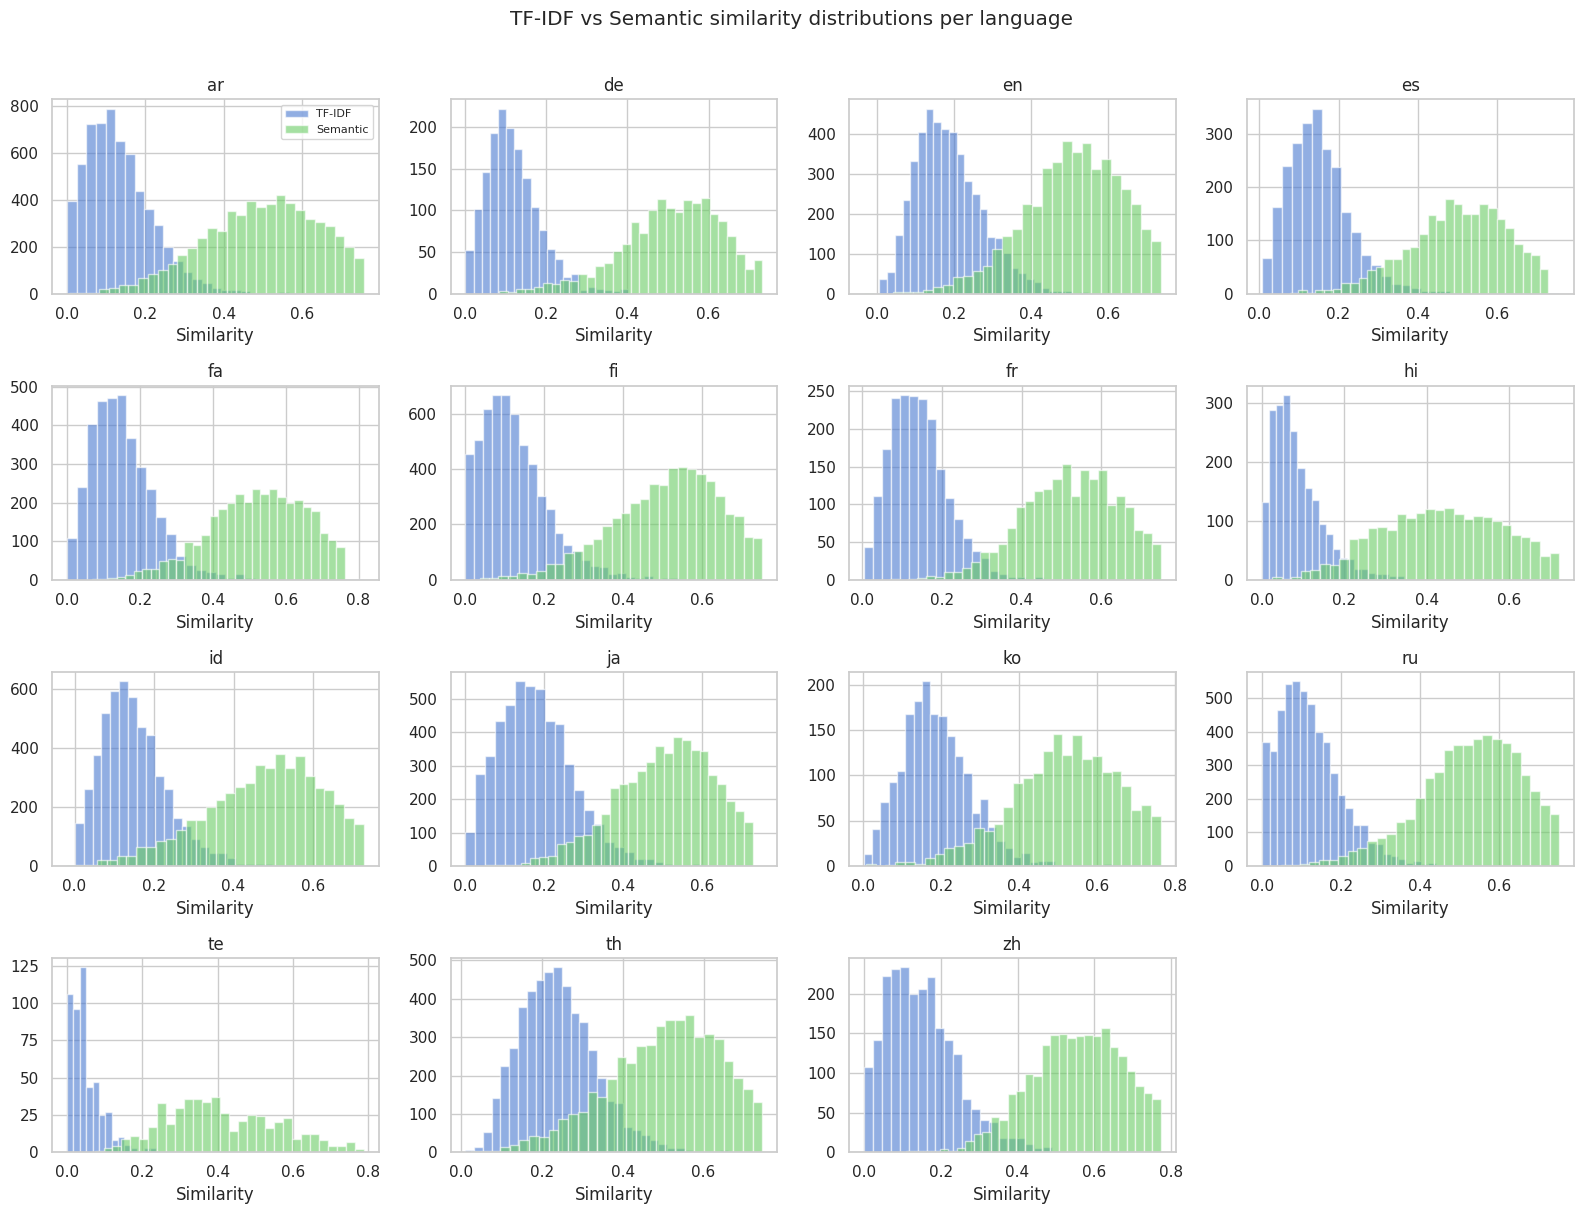

In [52]:
n_langs_plot = len(QUALIFYING_LANGS)
ncols        = 4
nrows        = (n_langs_plot + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3))
axes_flat = axes.flatten() if nrows > 1 else axes

for i, lang in enumerate(QUALIFYING_LANGS):
    ax   = axes_flat[i]
    sub  = df_full[df_full['language'] == lang]
    ax.hist(sub['tfidf_sim'],    bins=30, alpha=0.6,
            color=sns.color_palette('muted')[0], label='TF-IDF')
    ax.hist(sub['semantic_sim'], bins=30, alpha=0.6,
            color=sns.color_palette('muted')[2], label='Semantic')
    ax.set_title(lang)
    ax.set_xlabel('Similarity')
    if i == 0:
        ax.legend(fontsize=8)

for j in range(i + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.suptitle('TF-IDF vs Semantic similarity distributions per language', y=1.01)
plt.tight_layout()
plt.savefig(DATA_DIR / 'fig_per_language_distributions.png', dpi=120, bbox_inches='tight')
plt.show()

### 8.4  Qualitative Examples per Difficulty Tier

Concrete distractor examples sampled from each compound-score tier.
Shows how the Easy / Medium / Hard distinction manifests in the actual text
and what both raw scores look like for each tier.

In [57]:
for tier in ['easy', 'medium', 'hard']:
    subset = df_full[(df_full['difficulty'] == tier) & (df_full['language'].isin(["ru", "en"]))]
    if len(subset) == 0:
        continue
    row   = subset.sample(1, random_state=SEED).iloc[0]
    csim  = row['compound_sim']
    tsim  = row['tfidf_sim']
    ssim  = row['semantic_sim']
    lang  = row['language']
    query = row['query']
    dist  = str(row['distractor_text'])
    gold  = str(row['gold_judge_text'])
    print('\n' + '=' * 80)
    print(f'DIFFICULTY: {tier.upper()}  |  compound={csim:.4f}  '
          f'(tfidf={tsim:.4f}, semantic={ssim:.4f})  |  lang={lang}')
    print(f'QUERY:      {query}')
    print(f'DISTRACTOR: {dist}...')
    print(f'GOLD:       {gold}...')


DIFFICULTY: EASY  |  compound=0.7921  (tfidf=0.0863, semantic=0.4117)  |  lang=ru
QUERY:      Какая самая высокая точка в Белграде?
DISTRACTOR: Медведница () — горный массив к северу от Загреба, популярное место отдыха загребчан. 63 % территории покрыты широколиственным лесом, состав которого меняется с высотой. Самой высокой точкой Медведницы является гора Слеме, высота которой — 1033 метров над уровнем моря. На ней стоит знаменитая церковь Божьей Матери Слеменской — Королевы Хорватии (). На самой же вершине Слеме находится Загребская телебашня высотой в 169 метров. На северных и восточных склонах Медведницы располагаются горнолыжные трассы с различной степенью сложности. К вершине проложено шоссе и канатная дорога. На северном склоне регулярно проводятся международные соревнования по горнолыжному слалому под эгидой Международной федерации лыжного спорта....
GOLD:       Рядом со средневековым укрепленным городом Жрнов (12-15 век), на вершине Авалы, жители окрестных деревень построили